# Coarse Fog Masking 實作與測試 (真實影片版)

這份 Notebook 實作了專案 Proposal 中定義的 **Coarse Fog Masking (粗略遮罩)**。利用局部對比度、HSV 飽和度以及影像梯度，透過聯集投票機制來找出初步的起霧像素。

**成員 A 的任務**：請將真實的起霧影片放入資料夾中，修改下方 Cell 的 `video_path`，並不斷微調 `thresh_var`, `thresh_sat`, `thresh_grad` 這三個參數，直到遮罩能完美捕捉到水氣且不誤判正常場景為止。

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 設定 matplotlib 顯示大小
plt.rcParams['figure.figsize'] = [18, 12]

part 1: coarse fog mask

### 核心函式定義

In [2]:
def get_coarse_fog_mask(image_bgr, 
                        patch_size=15, 
                        thresh_var=0.015, 
                        thresh_sat=0.3, 
                        thresh_grad=0.15,
                        thresh_val=0.5):  # 🌟 新增明度閾值參數
    # 1. 影像預處理
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    
    # 特徵一：對比度特徵 (Contrast)
    mean_of_sq = cv2.blur(gray**2, (patch_size, patch_size))
    sq_of_mean = cv2.blur(gray, (patch_size, patch_size))**2
    variance = np.clip(mean_of_sq - sq_of_mean, 0, None)
    mask_contrast = variance < thresh_var
    
    # 特徵二 & 新增的特徵四：飽和度 (Saturation) 與 明度 (Value)
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1].astype(np.float32) / 255.0
    mask_sat = sat < thresh_sat
    
    val = hsv[:, :, 2].astype(np.float32) / 255.0
    mask_bright = val > thresh_val  # 🌟 新增：亮度必須大於閾值
    
    # 特徵三：梯度特徵 (Gradient)
    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.sqrt(sobelx**2 + sobely**2)
    mask_grad = grad_mag < thresh_grad
    
    # 決策：投票機制 (符合兩項以上)
    votes = mask_contrast.astype(np.uint8) + \
            mask_sat.astype(np.uint8) + \
            mask_grad.astype(np.uint8)
            
    # 🌟 關鍵修改：得票數 >= 2，【且】亮度必須夠高
    coarse_mask = ((votes >= 2) & mask_bright).astype(np.uint8) * 255
    
    # 形態學操作去噪
    kernel = np.ones((5, 5), np.uint8)
    coarse_mask = cv2.morphologyEx(coarse_mask, cv2.MORPH_OPEN, kernel)
    coarse_mask = cv2.morphologyEx(coarse_mask, cv2.MORPH_CLOSE, kernel)
    
    # 🌟 更新 debug 字典，加入 brightness
    debug_masks = {
        'contrast': (mask_contrast.astype(np.uint8) * 255),
        'saturation': (mask_sat.astype(np.uint8) * 255),
        'gradient': (mask_grad.astype(np.uint8) * 255),
        'brightness': (mask_bright.astype(np.uint8) * 255), # <--- 這裡加進去
        'votes_map': (votes * 85).astype(np.uint8)
    }
    
    return coarse_mask, debug_masks

### 讀取真實影片與視覺化
請將 `video_path` 替換為你們手邊的影片路徑。你可以透過改變 `frame_id` 來隨機抽查影片中的不同時間點，確保參數在整支影片中都具備泛化能力。

✅ 成功讀取第 100 幀，影像大小: (854, 480, 3)


C:\Users\USER\AppData\Local\Temp\ipykernel_22868\3520616412.py:73: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


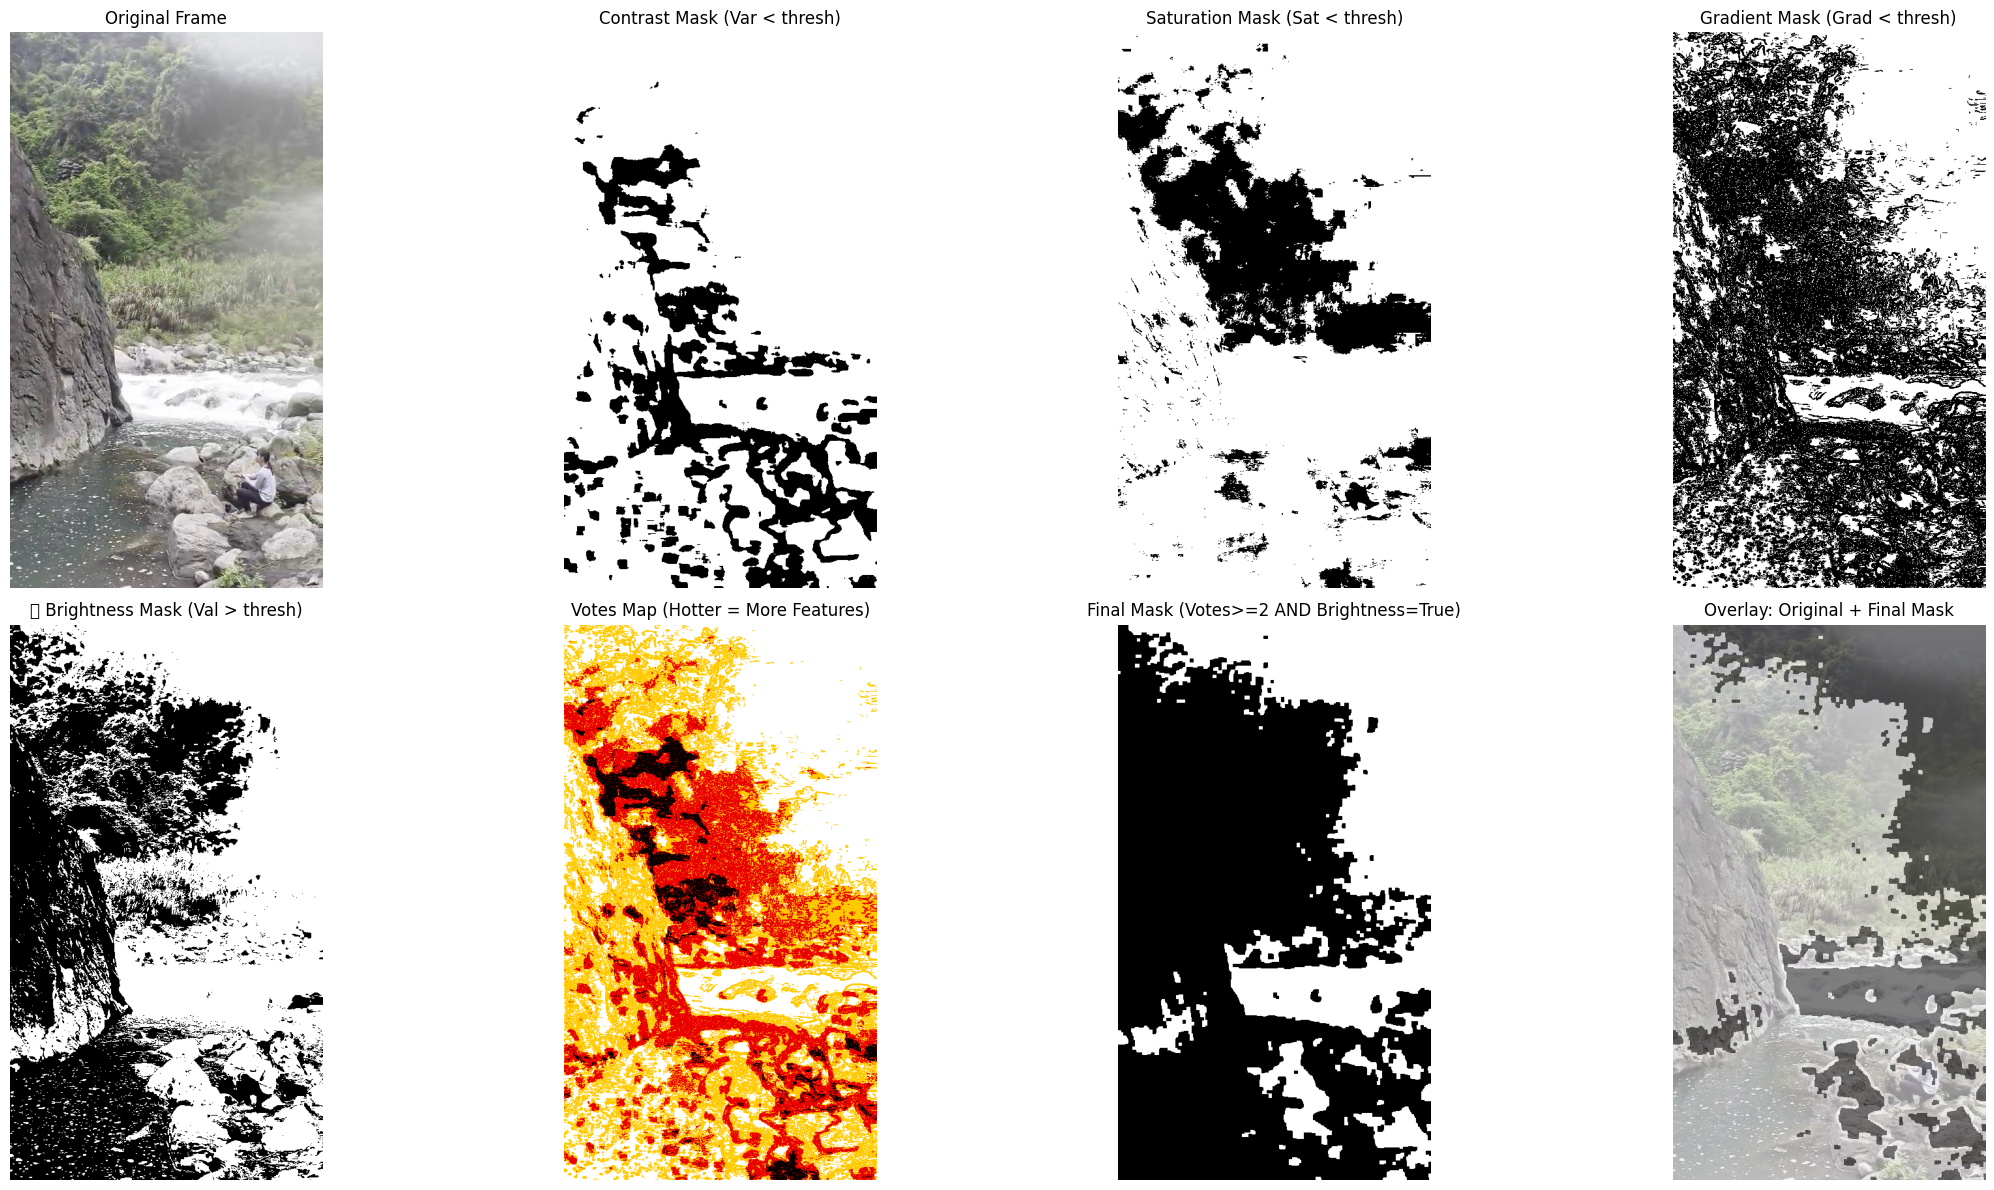

In [3]:
# ==========================================
# 1. 設定影片路徑與抽樣幀數
# ==========================================
video_path = './data/foggy_vid/1.mp4'  # <--- 在這裡換成你們的測試影片名稱
frame_id = 100                     # <--- 試著改成不同的數字 (例如 0, 50, 300) 來看不同時間點的霧氣

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
ret, frame = cap.read()

if not ret:
    print(f"⚠️ 無法讀取影片 '{video_path}' 或是 frame_id 超出範圍。請確認檔名是否正確且放在同一資料夾！")
    # 為了防呆，產生一張黑色測試圖避免報錯
    frame = np.zeros((720, 1280, 3), dtype=np.uint8)
else:
    print(f"✅ 成功讀取第 {frame_id} 幀，影像大小: {frame.shape}")
    # 如果手機拍的影片是 4K (3840x2160) 等高解析度，建議先縮小，加快演算法驗證速度
    # frame = cv2.resize(frame, (1280, 720))

# 執行函式 (記得補上 thresh_val 參數)
final_mask, debug = get_coarse_fog_mask(
    frame, 
    patch_size=15, 
    thresh_var=0.015,    # 放寬一點對比度
    thresh_sat=0.1,     # 放寬一點飽和度
    thresh_grad=0.15,    # 放寬一點梯度
    thresh_val=0.55     # 新增：亮度要大於 0.55 才算霧 (濾掉石頭)
)

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# ==========================================
# 繪製結果 (改成 2x4 的網格，共 8 格)
# ==========================================
fig, axes = plt.subplots(2, 4, figsize=(24, 12))

# --- 第一排：原圖與三大原始特徵 ---
axes[0, 0].imshow(frame_rgb)
axes[0, 0].set_title('Original Frame')
axes[0, 0].axis('off')

axes[0, 1].imshow(debug['contrast'], cmap='gray')
axes[0, 1].set_title('Contrast Mask (Var < thresh)')
axes[0, 1].axis('off')

axes[0, 2].imshow(debug['saturation'], cmap='gray')
axes[0, 2].set_title('Saturation Mask (Sat < thresh)')
axes[0, 2].axis('off')

axes[0, 3].imshow(debug['gradient'], cmap='gray')
axes[0, 3].set_title('Gradient Mask (Grad < thresh)')
axes[0, 3].axis('off')

# --- 第二排：新增的亮度特徵、投票結果與最終輸出 ---
axes[1, 0].imshow(debug['brightness'], cmap='gray')
axes[1, 0].set_title('🌟 Brightness Mask (Val > thresh)')
axes[1, 0].axis('off')

axes[1, 1].imshow(debug['votes_map'], cmap='hot')
axes[1, 1].set_title('Votes Map (Hotter = More Features)')
axes[1, 1].axis('off')

axes[1, 2].imshow(final_mask, cmap='gray')
axes[1, 2].set_title('Final Mask (Votes>=2 AND Brightness=True)')
axes[1, 2].axis('off')

# show the original image with the final mask overlaid (for better visualization)
axes[1, 3].imshow(frame_rgb)
axes[1, 3].imshow(final_mask, cmap='Greys', alpha=0.5)  # 半透明疊加
axes[1, 3].set_title('Overlay: Original + Final Mask')
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

part 2: homology transformation

In [4]:
import os
from tqdm import tqdm

In [5]:
def align_frames(frame_ref, frame_curr, mask_fog_ref=None, mask_fog_curr=None):
    """
    計算 frame_curr 到 frame_ref 的單應性矩陣，並回傳對齊後的影像。
    mask_fog: 255 代表霧，0 代表清晰。
    """
    # 1. 轉灰階
    gray_ref = cv2.cvtColor(frame_ref, cv2.COLOR_BGR2GRAY)
    gray_curr = cv2.cvtColor(frame_curr, cv2.COLOR_BGR2GRAY)
    
    # 2. 處理特徵擷取遮罩 (反轉：讓 255 變成可以搜尋特徵的區域)
    # 如果沒有傳入遮罩，就產生全白的遮罩 (整張圖都找)
    if mask_fog_ref is not None:
        valid_mask_ref = cv2.bitwise_not(mask_fog_ref)
    else:
        valid_mask_ref = np.ones_like(gray_ref) * 255
        
    if mask_fog_curr is not None:
        valid_mask_curr = cv2.bitwise_not(mask_fog_curr)
    else:
        valid_mask_curr = np.ones_like(gray_curr) * 255

    # 3. 初始化 SIFT 偵測器
    sift = cv2.SIFT_create()
    
    # 尋找特徵點 (Keypoints) 與描述子 (Descriptors)，並套用遮罩！
    kp_ref, des_ref = sift.detectAndCompute(gray_ref, mask=valid_mask_ref)
    kp_curr, des_curr = sift.detectAndCompute(gray_curr, mask=valid_mask_curr)
    
    # 4. 特徵點匹配 (使用 BFMatcher)
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des_curr, des_ref, k=2)
    
    # Lowe's ratio test (過濾掉品質不好的配對)
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)
            
    # 如果配對點太少，對齊會失敗
    MIN_MATCH_COUNT = 10
    if len(good_matches) > MIN_MATCH_COUNT:
        # 整理兩張圖配對到的座標點
        src_pts = np.float32([ kp_curr[m.queryIdx].pt for m in good_matches ]).reshape(-1, 1, 2)
        dst_pts = np.float32([ kp_ref[m.trainIdx].pt for m in good_matches ]).reshape(-1, 1, 2)
        
        # 5. 計算單應性矩陣 (Homography) + RANSAC 過濾
        H, ransac_mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
        
        # 6. 將當前影格扭曲 (Warp) 到參考影格的座標系
        h, w = frame_ref.shape[:2]
        aligned_curr = cv2.warpPerspective(frame_curr, H, (w, h))
        
        # 畫出特徵匹配圖 (供視覺化 debug)
        matches_mask = ransac_mask.ravel().tolist()
        draw_params = dict(matchColor=(0, 255, 0), singlePointColor=None,
                           matchesMask=matches_mask, flags=2)
        match_img = cv2.drawMatches(frame_curr, kp_curr, frame_ref, kp_ref, good_matches, None, **draw_params)
        
        return aligned_curr, H, match_img
    else:
        print(f"⚠️ 特徵點匹配不足！只有 {len(good_matches)} 點，需要至少 {MIN_MATCH_COUNT} 點。")
        return None, None, None

In [6]:
# ==========================================
# 測試區塊 (成員 B 真實影片對齊測試)
# ==========================================

def test_alignment_on_real_video():
	
	
	video_path = './data/foggy_vid/1.mp4'
	
	# 1. 檢查檔案路徑
	if not os.path.exists(video_path):
		print(f"⚠️ 找不到影片檔案：{video_path}，請確認路徑是否正確！")
		return 
	
	print("🎬 正在讀取影片並提取影格...")
	cap = cv2.VideoCapture(video_path)
	
	# 設定並讀取第 100 幀 (參考幀 Reference Frame)
	cap.set(cv2.CAP_PROP_POS_FRAMES, 100)
	ret_ref, frame_ref = cap.read()
	
	# 設定並讀取第 101 幀 (當前幀 Current Frame)
	cap.set(cv2.CAP_PROP_POS_FRAMES, 101)
	ret_curr, frame_curr = cap.read()
	
	cap.release()
	
	if not ret_ref or not ret_curr:
		print("⚠️ 無法讀取指定的影格，請確認影片長度是否超過 101 幀！")
		return
	
	print("🌫️ 正在呼叫成員 A 的函式計算 Coarse Fog Mask...")
	# 這裡的參數可以先填寫成員 A 剛剛測試出來覺得最穩定的那一組
	# (假設 get_coarse_fog_mask 已經在同一個檔案上方，或已經 import)
	mask_ref, _ = get_coarse_fog_mask(frame_ref, thresh_var=0.03, thresh_sat=0.4, thresh_grad=0.2, thresh_val=0.55)
	mask_curr, _ = get_coarse_fog_mask(frame_curr, thresh_var=0.03, thresh_sat=0.4, thresh_grad=0.2, thresh_val=0.55)
	
	print("🔗 正在執行 Global Alignment (特徵匹配與扭曲)...")
	aligned_curr, H, match_img = align_frames(frame_ref, frame_curr, mask_ref, mask_curr)
	
	if aligned_curr is None:
		print("❌ 對齊失敗，無法計算單應性矩陣 H。")
		return

	print("✅ 對齊成功！正在繪製結果...")
	# 轉 RGB 供 matplotlib 顯示
	frame_ref_rgb = cv2.cvtColor(frame_ref, cv2.COLOR_BGR2RGB)
	frame_curr_rgb = cv2.cvtColor(frame_curr, cv2.COLOR_BGR2RGB)
	aligned_curr_rgb = cv2.cvtColor(aligned_curr, cv2.COLOR_BGR2RGB)
	match_img_rgb = cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB)
	
	# 建立 2x2 網格來比較對齊前後的差異
	fig, axes = plt.subplots(2, 2, figsize=(20, 12))
	
	axes[0, 0].imshow(frame_ref_rgb)
	axes[0, 0].set_title('Reference Frame (Frame 100)')
	axes[0, 0].axis('off')
	
	axes[0, 1].imshow(frame_curr_rgb)
	axes[0, 1].set_title('Current Frame (Frame 101 - Unaligned)')
	axes[0, 1].axis('off')
	
	axes[1, 0].imshow(match_img_rgb)
	axes[1, 0].set_title('SIFT Feature Matches (Fog Areas Excluded)')
	axes[1, 0].axis('off')
	
	axes[1, 1].imshow(aligned_curr_rgb)
	axes[1, 1].set_title('Aligned Current Frame (Warped to Ref)')
	axes[1, 1].axis('off')
	
	plt.tight_layout()
	plt.show()
	
	# 印出算出來的單應性矩陣 H
	print("\n📊 計算出的單應性矩陣 (Homography Matrix H):")
	print(np.round(H, 3))

🎬 正在讀取影片並提取影格...
🌫️ 正在呼叫成員 A 的函式計算 Coarse Fog Mask...
🔗 正在執行 Global Alignment (特徵匹配與扭曲)...
✅ 對齊成功！正在繪製結果...


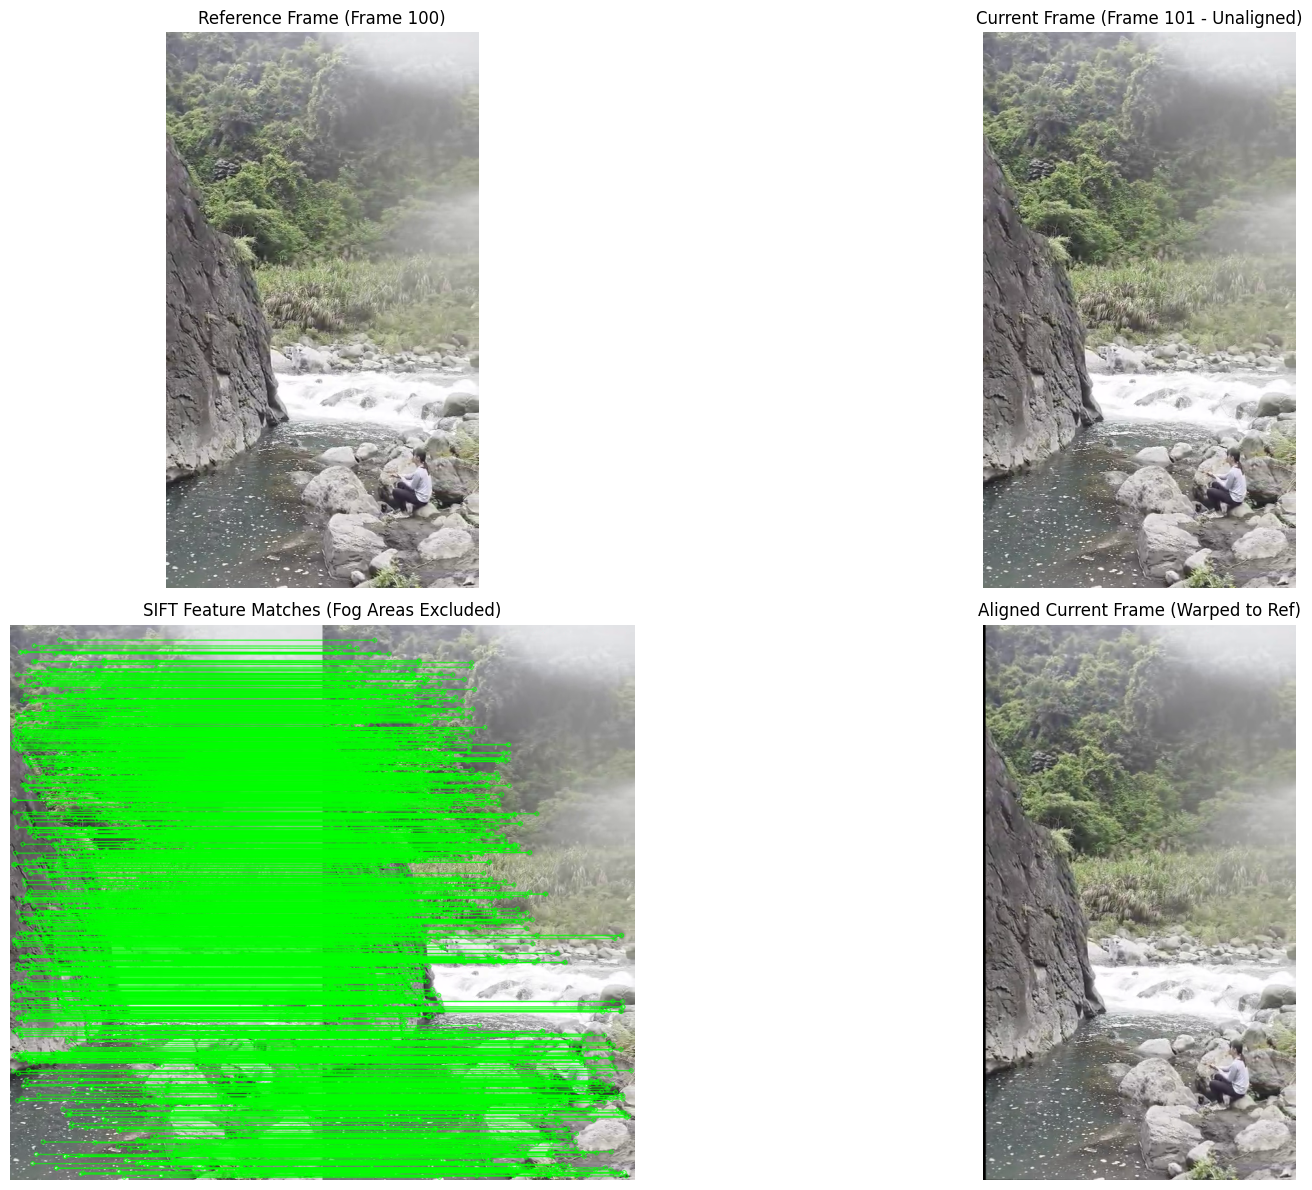


📊 計算出的單應性矩陣 (Homography Matrix H):
[[ 9.970e-01  0.000e+00  3.919e+00]
 [-3.000e-03  9.990e-01  7.700e-01]
 [-0.000e+00 -0.000e+00  1.000e+00]]


In [7]:
test_alignment_on_real_video()

In [13]:
def align_video_sequential(video_path, start_frame, end_frame):
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
    
    ret, frame_prev = cap.read()
    if not ret: return None, None
        
    h, w = frame_prev.shape[:2]
    
    # 🌟 新增：定義全景圖的「大畫布」尺寸
    pano_w = int(w * 3.0)  # 寬度放大 3 倍
    pano_h = int(h * 1.5)  # 高度放大 1.5 倍
    
    # 🌟 新增：設定平移偏移量 (把第一張圖放在畫布的 x=w/2, y=h/4 的位置)
    offset_x = int(w * 0.5)
    offset_y = int(h * 0.25)
    
    # 建立平移矩陣
    T_offset = np.array([
        [1, 0, offset_x],
        [0, 1, offset_y],
        [0, 0, 1]
    ], dtype=np.float32)
    
    mask_prev, _ = get_coarse_fog_mask(frame_prev, thresh_val=0.55)
    valid_mask_prev = cv2.bitwise_not(mask_prev)
    gray_prev = cv2.cvtColor(frame_prev, cv2.COLOR_BGR2GRAY)
    
    sift = cv2.SIFT_create()
    kp_prev, des_prev = sift.detectAndCompute(gray_prev, mask=valid_mask_prev)
    
    # 🌟 核心修改：將平移矩陣 T_offset 乘在累積矩陣前面
    H_accumulated = np.eye(3, dtype=np.float32)
    H_pano_initial = np.matmul(T_offset, H_accumulated) 
    
    # 把第一幀畫在大畫布上
    frame_prev_warped = cv2.warpPerspective(frame_prev, H_pano_initial, (pano_w, pano_h))
    
    aligned_video_tensor = [frame_prev_warped]
    H_list = [H_pano_initial.copy()] # 存入帶有平移的全景矩陣
    
    bf = cv2.BFMatcher()
    
    print(f"🔗 開始連鎖對齊：第 {start_frame} 到 {end_frame} 幀")
    from tqdm import tqdm
    for i in tqdm(range(start_frame + 1, end_frame + 1)):
        ret, frame_curr = cap.read()
        if not ret: break
            
        mask_curr, _ = get_coarse_fog_mask(frame_curr, thresh_val=0.55)
        valid_mask_curr = cv2.bitwise_not(mask_curr)
        gray_curr = cv2.cvtColor(frame_curr, cv2.COLOR_BGR2GRAY)
        kp_curr, des_curr = sift.detectAndCompute(gray_curr, mask=valid_mask_curr)
        
        matches = bf.knnMatch(des_curr, des_prev, k=2)
        good_matches = [m for m, n in matches if m.distance < 0.75 * n.distance]
        
        if len(good_matches) > 10:
            src_pts = np.float32([kp_curr[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
            dst_pts = np.float32([kp_prev[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
            H_curr_to_prev, _ = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
            
            if H_curr_to_prev is not None:
                H_accumulated = np.matmul(H_accumulated, H_curr_to_prev)
                kp_prev, des_prev = kp_curr, des_curr
            else:
                print(f"⚠️ 第 {i} 幀 RANSAC 失敗")
        
        # 🌟 核心修改：每次變形時，都套用大畫布的平移矩陣
        H_pano_curr = np.matmul(T_offset, H_accumulated)
        aligned_curr = cv2.warpPerspective(frame_curr, H_pano_curr, (pano_w, pano_h))
        
        aligned_video_tensor.append(aligned_curr)
        H_list.append(H_pano_curr.copy())
            
    cap.release()
    return np.array(aligned_video_tensor), H_list

In [14]:
if __name__ == "__main__":
    video_path = './data/foggy_vid/1.mp4'
    
    # 抓取一段 30 幀的區間進行測試 (例如 100 ~ 130)
    aligned_tensor, _ = align_video_sequential(video_path, start_frame=100, end_frame=130)
    
    print(f"\n🎉 對齊完成！獲得矩陣維度: {aligned_tensor.shape} (幀數, 高, 寬, 通道數)")
    
    # (選擇性) 將對齊後的結果輸出成一支小影片，親眼看看背景有沒有被「釘死」不動
    h, w = aligned_tensor.shape[1:3]
    out = cv2.VideoWriter('aligned_output.mp4', cv2.VideoWriter_fourcc(*'mp4v'), 30, (w, h))
    for frame in aligned_tensor:
        out.write(frame)
    out.release()
    print("🎬 已輸出預覽影片至 'aligned_output.mp4'")

🔗 開始連鎖對齊：第 100 到 130 幀


100%|██████████| 30/30 [00:02<00:00, 14.69it/s]



🎉 對齊完成！獲得矩陣維度: (31, 1281, 1440, 3) (幀數, 高, 寬, 通道數)
🎬 已輸出預覽影片至 'aligned_output.mp4'


part 3: temporal fusion & repainting

In [ ]:
def process_dynamic_fusion(video_path, start_frame, aligned_tensor, H_list):
    """
    動態去霧：將乾淨背景拉回原始影格位置進行融合。
    """
    T, H, W, C = aligned_tensor.shape
    
    # 步驟一：計算時序中位數 (忽略黑邊，得到全域乾淨背景)
    tensor_float = aligned_tensor.astype(np.float32)
    tensor_float[np.all(tensor_float == 0, axis=-1)] = np.nan
    clean_bg_ref = np.nanmedian(tensor_float, axis=0)
    clean_bg_ref = np.nan_to_num(clean_bg_ref, nan=0.0).astype(np.uint8)
    
    cap = cv2.VideoCapture(video_path)
    final_dehazed_frames = []
    
    print("🎨 正在執行動態視野融合...")
    for t in tqdm(range(T)):
        # 1. 讀取「原始、沒對齊過」的影格
        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame + t)
        ret, frame_raw = cap.read()
        if not ret: break
        
        # 2. 將乾淨背景拉回當前影格的視野 (使用 H 的反矩陣)
        H_inv = np.linalg.inv(H_list[t])
        bg_at_current_view = cv2.warpPerspective(clean_bg_ref, H_inv, (W, H))
        
        # 3. 生成遮罩 (建議此處使用成員 A 的 coarse mask)
        mask_coarse, _ = get_coarse_fog_mask(frame_raw) 
        mask_float = cv2.GaussianBlur(mask_coarse.astype(np.float32)/255.0, (41, 41), 0)
        mask_3c = np.stack([mask_float]*3, axis=-1)
        
        # 4. Alpha Blending：在原始畫面中，把起霧的地方換成拉回來的乾淨背景
        blended = frame_raw * (1.0 - mask_3c) + bg_at_current_view * mask_3c
        final_dehazed_frames.append(blended.astype(np.uint8))
        
    cap.release()
    return final_dehazed_frames

In [ ]:
video_path = './data/foggy_vid/1.mp4'

# --- 執行流程 ---
# 1. 成員 B 對齊
aligned_data, matrices = align_video_sequential(video_path, 0, 300)

# 2. 成員 C 去霧 (保持原始動態)
dehazed_video = process_dynamic_fusion(video_path, 0, aligned_data, matrices)

# 3. 儲存影片 (mp4v + .mp4)
out = cv2.VideoWriter('dehazed_output.mp4', cv2.VideoWriter_fourcc(*'mp4v'), 30, (w, h))
for f in dehazed_video:
    out.write(f)
out.release()

🔗 開始連鎖對齊：第 0 到 300 幀


100%|██████████| 300/300 [00:23<00:00, 12.51it/s]


⏳ 正在計算全域乾淨背景 (這步最花時間，請稍候)...
🎨 正在執行動態視野融合...


100%|██████████| 301/301 [00:14<00:00, 20.40it/s]


✅ 處理完成，已儲存為 dehazed_output.mp4


In [ ]:
print("🔍 正在計算全域乾淨背景 (Temporal Median)...")
T, H, W, C = aligned_data.shape

# 1. 忽略黑邊計算中位數
tensor_float = aligned_data.astype(np.float32)
tensor_float[np.all(tensor_float == 0, axis=-1)] = np.nan

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    clean_bg_ref = np.nanmedian(tensor_float, axis=0)
    
clean_bg_ref = np.nan_to_num(clean_bg_ref, nan=0.0).astype(np.uint8)

# 2. 儲存圖片到本機
cv2.imwrite('clean_bg_panorama.jpg', clean_bg_ref)
print("✅ 已儲存全景圖至 'clean_bg_panorama.jpg'")

# 3. 使用 matplotlib 顯示出來
# OpenCV 預設是 BGR，matplotlib 顯示需要 RGB
clean_bg_rgb = cv2.cvtColor(clean_bg_ref, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(18, 12))
plt.imshow(clean_bg_rgb)
plt.title("Clean Background Panorama (Temporal Median)")
plt.axis('off')
plt.show()

🔍 正在計算全域乾淨背景 (Temporal Median)...


MemoryError: Unable to allocate 12.4 GiB for an array with shape (301, 1281, 1440, 3) and data type int64